# Diseño del sistema de control de actitud de un satélite

In [1]:
import numpy as np
import control as ctrl
import matplotlib.pyplot as plt

## Definición del sistema

Diseñar un compensador para la planta:

$$ \dot{\mathbf{x}}=\begin{bmatrix}
0&1\\
0&0\\
\end{bmatrix}\mathbf{x}+\begin{bmatrix}
0\\
1
\end{bmatrix}u$$

$$ y=\begin{bmatrix}
1&0\end{bmatrix}\mathbf{x}.$$

que ubique los polos de lazo cerrado tal que $\omega_n =1$ y $\zeta=0.707$:

In [2]:
A=[[0,1],[0,0]]
B=[[0],[1]]
C=[[1,0]]
D=[[0]]
sys=ctrl.ss(A,B,C,D)

## Análisis de controlabilidad y observabilidad

Calculamos el rango de las matrices de observabilidad y de controlabilidad. Con las matrices $\mathbf B$ y $\mathbf C$ dadas, el sistema es observable y controlable (rango 2). Sin embargo, no lo sería si se midiera la velocidad en lugar de la posición, $\mathbf C = [0\;\;1]$, o si se actuara sobre la posición en lugar de la aceleración, $\mathbf B = [1\;\;0]^T$:

In [3]:
print("Observabilidad con C dada:", np.linalg.matrix_rank(ctrl.obsv(A,C)))
print("Observabilidad midiendo la velocidad:", np.linalg.matrix_rank(ctrl.obsv(A,[[0,1]])))
print("Controlabilidad con B dada:", np.linalg.matrix_rank(ctrl.ctrb(A,B)))
print("Controlabilidad con B=[1 0]':", np.linalg.matrix_rank(ctrl.ctrb(A,[[1],[0]])))

Observabilidad con C dada: 2
Observabilidad midiendo la velocidad: 1
Controlabilidad con B dada: 2
Controlabilidad con B=[1 0]': 1


Para cumplir con los requerimientos debemos ubicar los polos en $\alpha_c = -0.707 \pm 0.707j$.

## Ley de control

Usando el comando `acker` o `place` obtenemos la ley de control que ubica los polos del sistema donde queremos.

In [4]:
wnc=1
zetac=np.sqrt(2)/2
polyc=[1,2*zetac*wnc,wnc**2]
alpha_c =np.roots(polyc)
print(alpha_c)

[-0.70710678+0.70710678j -0.70710678-0.70710678j]


In [5]:
K = ctrl.place(A,B,alpha_c)
print(K)

[[1.         1.41421356]]


Usando `acker` obtenemos el mismo resultado. Notar que `acker` devuelve un vector 1-D, por lo que lo convertimos en una matriz fila para poder operar con él:

In [6]:
K = np.atleast_2d(ctrl.acker(A,B,alpha_c))
print(K)

[[1.         1.41421356]]


Controlamos que las cuentas estén bien hechas, verificando que los autovalores de $\mathbf{A}-\mathbf{BK}$ den donde tienen que dar:

In [7]:
l,_=np.linalg.eig(A-B@K)
print(l)

[-0.70710678+0.70710678j -0.70710678-0.70710678j]


## Diseño del estimador

Ahora ubicamos los polos del estimador 5 veces más rápidos ($\omega_n=5$) y con $\zeta=0.5$.

In [8]:
wne=5
zetae=0.5
polye =[1,2*zetae*wne,wne**2]
rootse=np.roots(polye)
print(rootse)

[-2.5+4.33012702j -2.5-4.33012702j]


In [9]:
Lt=ctrl.place(sys.A.T,sys.C.T,rootse).T
print(Lt)

[[ 5.]
 [25.]]


## Definición del sistema de control

Expresando las ecuaciones de estado del controlador $D_c$ nos queda:

$$\begin{align*}
\mathbf{\dot{\hat{x}}}&=(\mathbf{A-BK-LC}) \mathbf{\hat {x}}+\mathbf{L}y\\
u&=-\mathbf{K}\mathbf{\hat{x}}\end{align*}$$

In [10]:
Dc=ctrl.ss(A-B@K-Lt@C,Lt,-K,[0])
ctrl.tf(Dc)

TransferFunction(
array([-40.35533906, -25.        ]),
array([ 1.        ,  6.41421356, 33.07106781]),
outputs=1, inputs=1)

Con este controlador podemos hacer un análisis del sistema igual que lo hacíamos en control clásico. La función de transferencia de lazo es $-D_c(s)G(s)$, porque el signo de la realimentación ya está incluido en $D_c$:

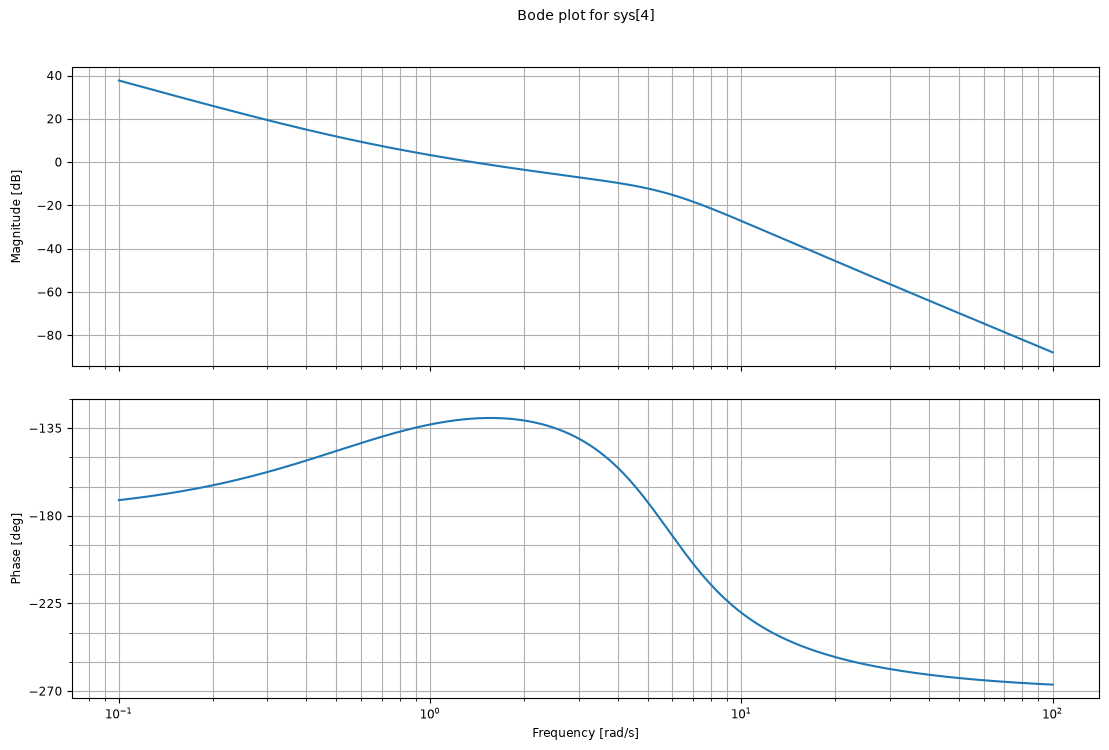

In [11]:
_=ctrl.bode(sys*-Dc,dB=True)
plt.gcf().set_size_inches(12,8)

In [12]:
gm, pm, wcg, wcp = ctrl.margin(sys*-Dc)
print(f"Margen de ganancia: {ctrl.mag2db(gm):.1f} dB, margen de fase: {pm:.1f}°")

Margen de ganancia: 13.3 dB, margen de fase: 49.9°


Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


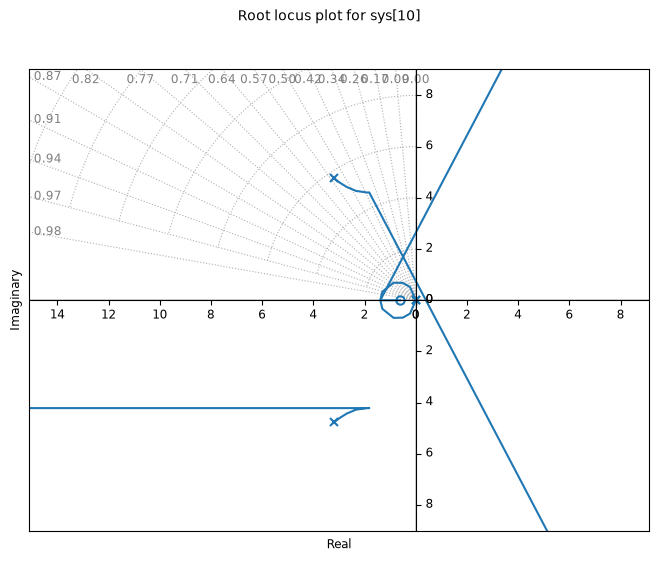

In [13]:
_=ctrl.rlocus(sys*-Dc,grid=True)
plt.gcf().set_size_inches(8,6)

Podemos ver que este diseño tiene un margen de fase de aproximadamente 50°.

## Con estimador reducido

Pondremos ahora el polo del estimador en $-5$ rad/s.

In [14]:
polesered=[-5]
Aaa=sys.A[0:1,0:1]
Aab=sys.A[0:1,1:]
Aba=sys.A[1:,0:1]
Abb=sys.A[1:,1:]

Ba = sys.B[0:1,:]
Bb = sys.B[1:,:]

In [15]:
Ltred = np.atleast_2d(ctrl.acker(Abb.T,Aab.T,polesered)).T
Ltred

array([[5.]])

Ahora podemos obtener el controlador con estimador reducido mediante las ecuaciones vistas en teoría. Para esto necesitamos separar la parte de $\mathbf K$ que multiplica al estado medido ($K_a$) de la que multiplica a los no medidos ($\mathbf{K_b}$).

## Definición del sistema controlador con estimador de orden reducido

In [16]:
Ka=K[:,0:1]
Kb=K[:,1:]

Ar = Abb-Ltred@Aab-(Bb-Ltred@Ba)@Kb
Br = Ar@Ltred + Aba - Ltred@Aaa - (Bb-Ltred@Ba)@Ka
Cr = -Kb
Dr = -Ka-Kb@Ltred

In [17]:
Dcr = ctrl.ss(Ar,Br,Cr,Dr)
ctrl.tf(-Dcr)

TransferFunction(
array([8.07106781, 5.        ]),
array([1.        , 6.41421356]),
outputs=1, inputs=1)

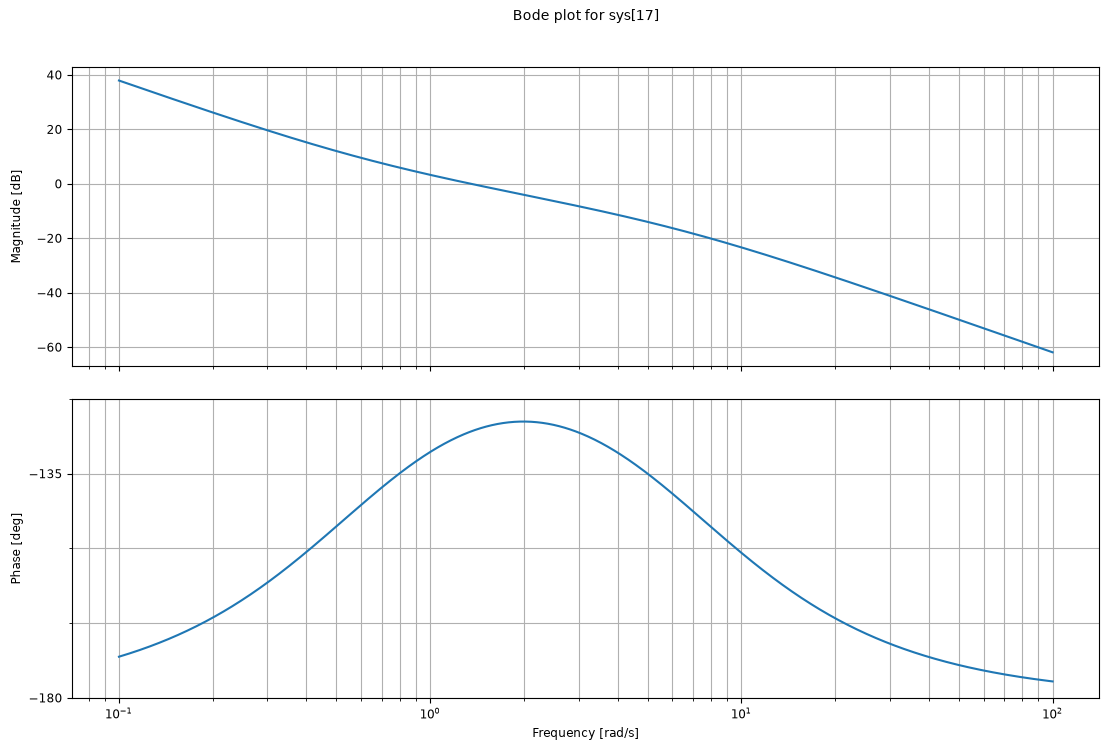

In [18]:
_=ctrl.bode((-Dcr*sys),dB=True)
plt.gcf().set_size_inches(12,8)

In [19]:
gm, pm, wcg, wcp = ctrl.margin(-Dcr*sys)
print(f"Margen de fase: {pm:.1f}°")

Margen de fase: 53.5°


Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.


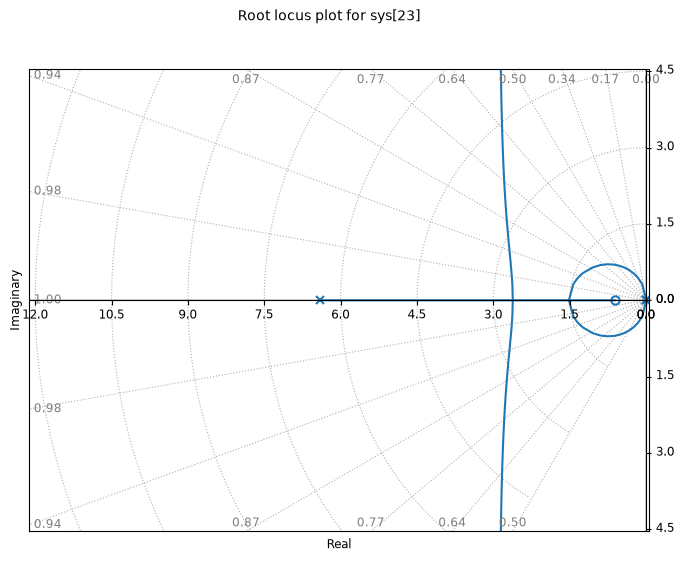

In [20]:
_=ctrl.rlocus(-Dcr*sys)
plt.gcf().set_size_inches(8,6)

Con el estimador reducido el controlador es de primer orden y el margen de fase es algo mayor, de aproximadamente 53°. En este caso no tiene sentido hablar de margen de ganancia: la fase de la función de lazo sólo vale $-180°$ en $\omega \rightarrow 0$, y el lugar de las raíces muestra que el lazo cerrado es estable para cualquier ganancia positiva.